In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_PATH = PROJECT_ROOT / "data" / "sales_data.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Project root: C:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main
Dataset path: C:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\data\sales_data.csv
Output directory: C:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

raw_df = pd.read_csv(DATA_PATH)

required_columns = {"Date", "Sales"}
missing_columns = required_columns - set(raw_df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

raw_df["Date"] = pd.to_datetime(raw_df["Date"], errors="coerce")
raw_df["Sales"] = pd.to_numeric(raw_df["Sales"], errors="coerce")

print("Original shape:", raw_df.shape)
print("\nMissing values:")
print(raw_df.isnull().sum())

print("\nDuplicate rows:", raw_df.duplicated().sum())

df = raw_df.dropna(subset=["Date", "Sales"]).copy()
df = df.sort_values("Date").reset_index(drop=True)

df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()

if df["Date"].duplicated().any():
    raise ValueError("Duplicate months found in the dataset.")

df = df.set_index("Date").asfreq("MS")

if df["Sales"].isnull().any():
    raise ValueError("Missing monthly sales observations detected.")

if len(df) < 8:
    raise ValueError("At least 8 monthly observations are recommended.")

print("\nCleaned shape:", df.shape)
print("Date range:", df.index.min(), "to", df.index.max())

display(df.head())

Original shape: (24, 2)

Missing values:
Date     0
Sales    0
dtype: int64

Duplicate rows: 0

Cleaned shape: (24, 1)
Date range: 2024-01-01 00:00:00 to 2025-12-01 00:00:00


,Sales
Date,
2024-01-01,120
2024-02-01,125
2024-03-01,130
2024-04-01,128
2024-05-01,135


In [3]:
sales = df["Sales"]

print("Total months:", len(sales))
print("Average sales:", round(sales.mean(), 2))
print("Median sales:", round(sales.median(), 2))
print("Minimum sales:", sales.min())
print("Maximum sales:", sales.max())
print("Standard deviation:", round(sales.std(), 2))

highest_month = sales.idxmax()
lowest_month = sales.idxmin()

print("\nHighest sales month:", highest_month.strftime("%B %Y"))
print("Highest sales value:", sales.max())

print("\nLowest sales month:", lowest_month.strftime("%B %Y"))
print("Lowest sales value:", sales.min())

display(sales.describe().to_frame(name="Sales"))

Total months: 24
Average sales: 173.04
Median sales: 172.5
Minimum sales: 120
Maximum sales: 230
Standard deviation: 34.53

Highest sales month: December 2025
Highest sales value: 230

Lowest sales month: January 2024
Lowest sales value: 120


,Sales
count,24.000000
mean,173.041667
std,34.525956
min,120.000000
25%,143.750000
50%,172.500000
75%,201.250000
max,230.000000


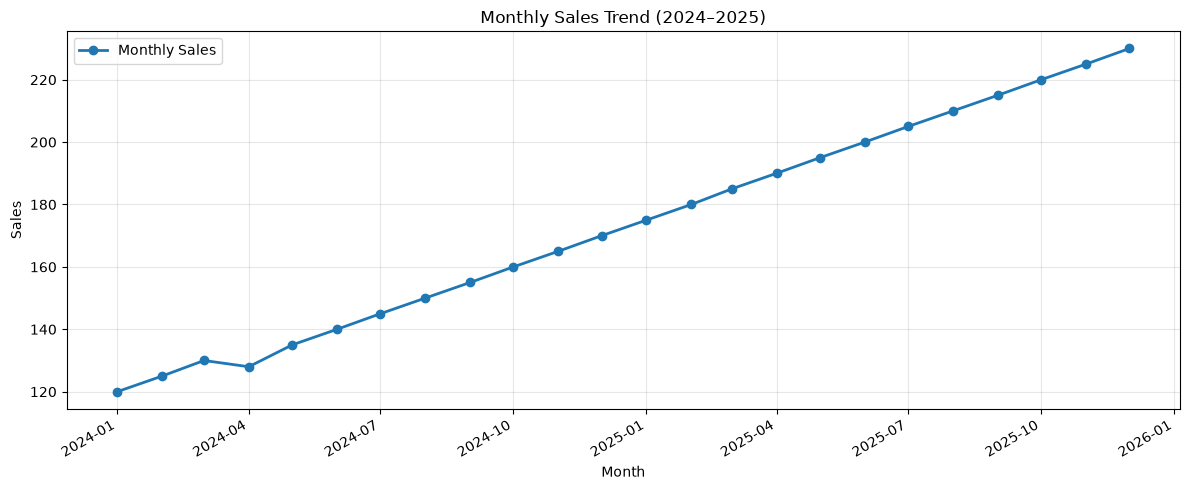

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    sales.index,
    sales,
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

ax.set_title("Monthly Sales Trend (2024–2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
analysis_df = df.copy()

analysis_df["Sales_Change"] = analysis_df["Sales"].diff()

analysis_df["Sales_Change_Percentage"] = (
    analysis_df["Sales"].pct_change() * 100
)

display(
    analysis_df[
        ["Sales", "Sales_Change", "Sales_Change_Percentage"]
    ].round(2)
)

growth_df = analysis_df.dropna(
    subset=["Sales_Change_Percentage"]
)

best_growth_month = growth_df["Sales_Change_Percentage"].idxmax()
worst_growth_month = growth_df["Sales_Change_Percentage"].idxmin()

print(
    "Largest monthly increase:",
    best_growth_month.strftime("%B %Y"),
    round(growth_df.loc[best_growth_month, "Sales_Change_Percentage"], 2),
    "%"
)

print(
    "Largest monthly decrease:",
    worst_growth_month.strftime("%B %Y"),
    round(growth_df.loc[worst_growth_month, "Sales_Change_Percentage"], 2),
    "%"
)

,Sales,Sales_Change,Sales_Change_Percentage
Date,,,
2024-01-01,120,NaN,NaN
2024-02-01,125,5.0,4.17
2024-03-01,130,5.0,4.00
2024-04-01,128,-2.0,-1.54
2024-05-01,135,7.0,5.47
2024-06-01,140,5.0,3.70
2024-07-01,145,5.0,3.57
2024-08-01,150,5.0,3.45
2024-09-01,155,5.0,3.33


Largest monthly increase: May 2024 5.47 %
Largest monthly decrease: April 2024 -1.54 %


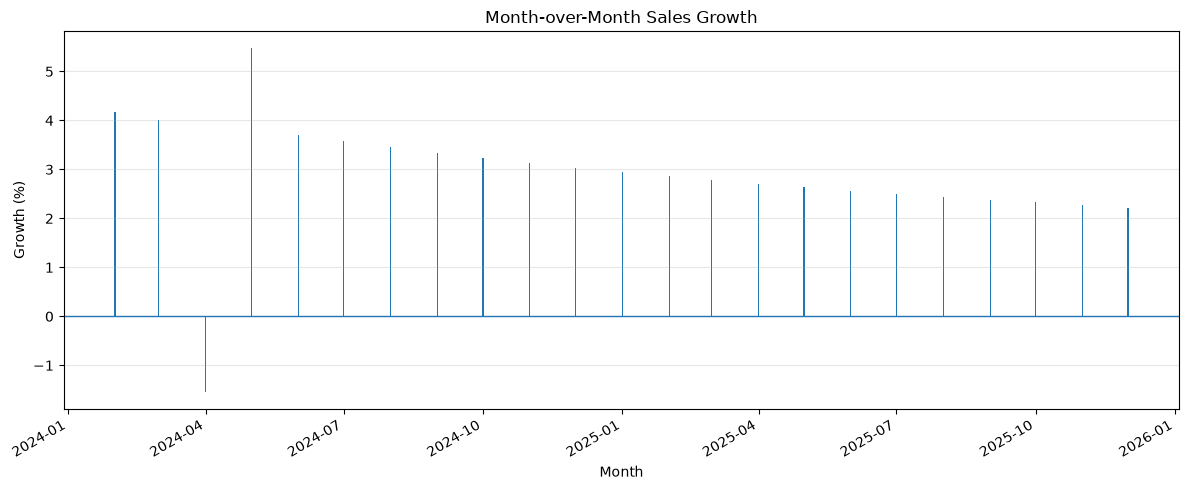

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    growth_df.index,
    growth_df["Sales_Change_Percentage"]
)

ax.axhline(0, linewidth=1)

ax.set_title("Month-over-Month Sales Growth")
ax.set_xlabel("Month")
ax.set_ylabel("Growth (%)")
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "monthly_sales_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
horizon = 2

train = sales.iloc[:-horizon]
test = sales.iloc[-horizon:]

print(
    "Training period:",
    train.index.min().strftime("%b %Y"),
    "to",
    train.index.max().strftime("%b %Y")
)

print(
    "Validation period:",
    test.index.min().strftime("%b %Y"),
    "to",
    test.index.max().strftime("%b %Y")
)

display(test.to_frame(name="Actual Sales"))

Training period: Jan 2024 to Oct 2025
Validation period: Nov 2025 to Dec 2025


,Actual Sales
Date,
2025-11-01,225
2025-12-01,230


In [8]:
baseline_forecast = pd.Series(
    [train.iloc[-1]] * len(test),
    index=test.index,
    name="Baseline"
)

display(
    pd.concat(
        [
            test.rename("Actual"),
            baseline_forecast
        ],
        axis=1
    )
)

,Actual,Baseline
Date,,
2025-11-01,225,220
2025-12-01,230,220


In [9]:
model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

fitted_model = model.fit(optimized=True)

forecast = fitted_model.forecast(
    len(test)
).rename("Exponential Smoothing")

comparison = pd.concat(
    [
        test.rename("Actual"),
        baseline_forecast,
        forecast
    ],
    axis=1
)

display(comparison.round(2))

,Actual,Baseline,Exponential Smoothing
2025-11-01,225,220,224.63
2025-12-01,230,220,229.40


In [10]:
def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = mean_squared_error(
        actual,
        predicted
    ) ** 0.5

    return {
        "MAE": mae,
        "RMSE": rmse
    }


metrics = pd.DataFrame({
    "Baseline": evaluate_forecast(
        test,
        baseline_forecast
    ),
    "Exponential Smoothing": evaluate_forecast(
        test,
        forecast
    )
}).T

display(metrics.round(3))

baseline_mae = metrics.loc["Baseline", "MAE"]
model_mae = metrics.loc["Exponential Smoothing", "MAE"]

if baseline_mae > 0:
    improvement = (
        (baseline_mae - model_mae) / baseline_mae
    ) * 100

    print(f"MAE reduction compared with baseline: {improvement:.2f}%")

print(
    "\nNote: Metrics are based on only two validation months."
)

,MAE,RMSE
Baseline,7.500,7.906
Exponential Smoothing,0.486,0.500


MAE reduction compared with baseline: 93.52%

Note: Metrics are based on only two validation months.


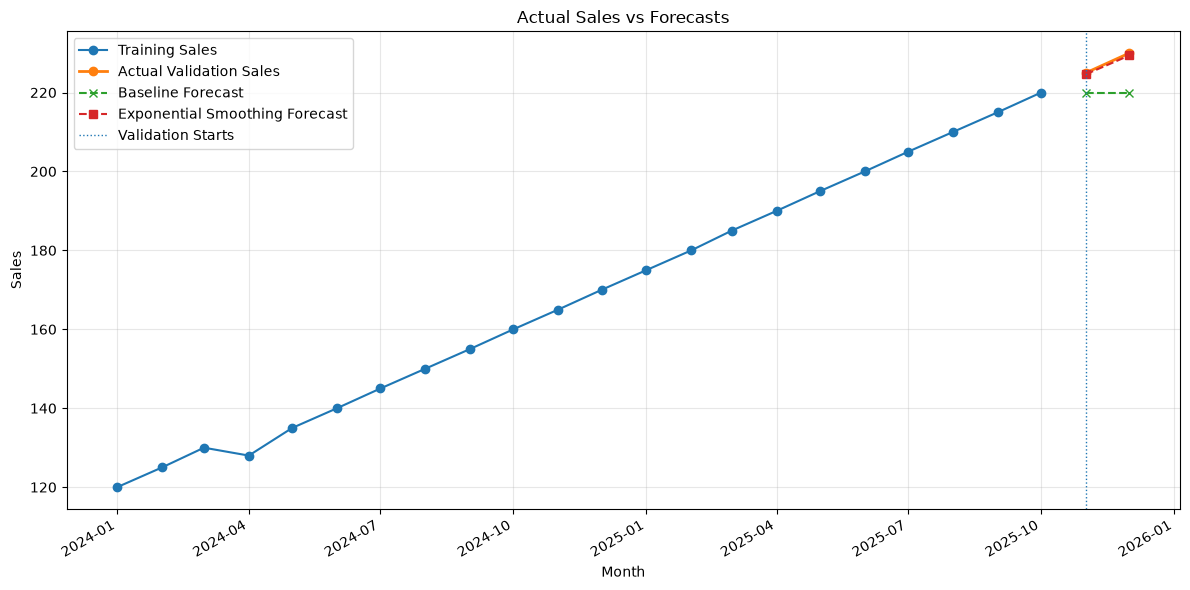

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    train.index,
    train,
    marker="o",
    label="Training Sales"
)

ax.plot(
    test.index,
    test,
    marker="o",
    linewidth=2,
    label="Actual Validation Sales"
)

ax.plot(
    baseline_forecast.index,
    baseline_forecast,
    marker="x",
    linestyle="--",
    label="Baseline Forecast"
)

ax.plot(
    forecast.index,
    forecast,
    marker="s",
    linestyle="--",
    label="Exponential Smoothing Forecast"
)

ax.axvline(
    test.index[0],
    linestyle=":",
    linewidth=1,
    label="Validation Starts"
)

ax.set_title("Actual Sales vs Forecasts")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "sales_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Forecast Sales
Date,
2026-01-01,234.67
2026-02-01,239.45
2026-03-01,244.24


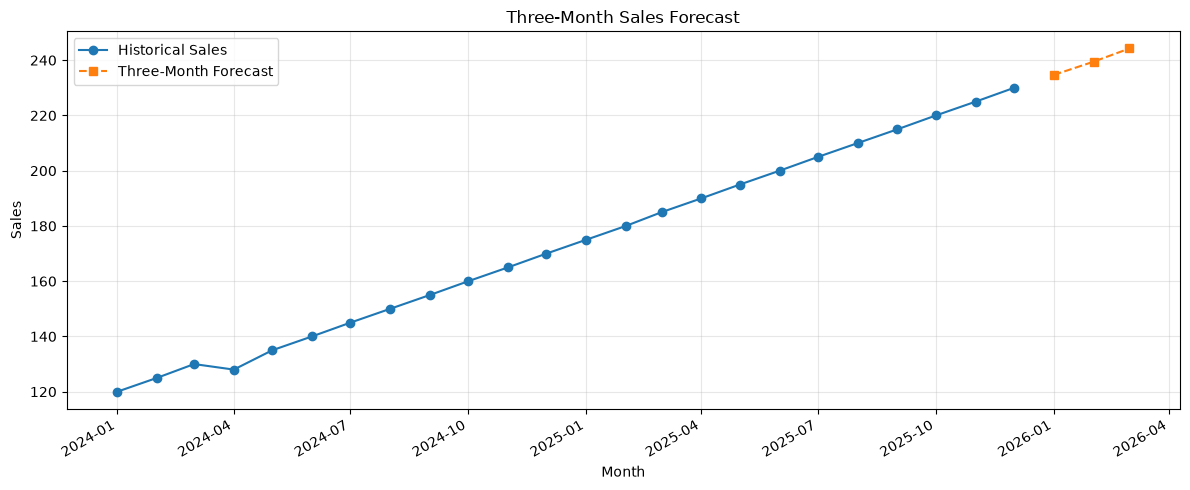

In [12]:
final_model = ExponentialSmoothing(
    sales,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

future_forecast = final_model.forecast(3)

future_forecast.name = "Forecast Sales"
future_forecast.index.name = "Date"

display(
    future_forecast.to_frame().round(2)
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    sales.index,
    sales,
    marker="o",
    label="Historical Sales"
)

ax.plot(
    future_forecast.index,
    future_forecast,
    marker="s",
    linestyle="--",
    label="Three-Month Forecast"
)

ax.set_title("Three-Month Sales Forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "three_month_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
start_sales = sales.iloc[0]
end_sales = sales.iloc[-1]

net_change = end_sales - start_sales

net_change_percentage = (
    net_change / start_sales
) * 100 if start_sales != 0 else 0

print("BUSINESS INSIGHTS")
print("-" * 40)

print(f"Starting sales: {start_sales:.2f}")
print(f"Ending sales: {end_sales:.2f}")
print(f"Net sales change: {net_change:.2f}")
print(f"Overall percentage change: {net_change_percentage:.2f}%")

print(f"Average monthly sales: {sales.mean():.2f}")

print(
    f"Highest sales month: {highest_month:%B %Y}"
)

print(
    f"Lowest sales month: {lowest_month:%B %Y}"
)

print("\nRecommendations:")
print("1. Investigate months with unusual sales changes.")
print("2. Use forecasts as planning estimates, not guarantees.")
print("3. Collect longer historical data for stronger forecasts.")
print("4. Include promotions, pricing, and holidays in future analysis.")

BUSINESS INSIGHTS
----------------------------------------
Starting sales: 120.00
Ending sales: 230.00
Net sales change: 110.00
Overall percentage change: 91.67%
Average monthly sales: 173.04
Highest sales month: December 2025
Lowest sales month: January 2024

Recommendations:
1. Investigate months with unusual sales changes.
2. Use forecasts as planning estimates, not guarantees.
3. Collect longer historical data for stronger forecasts.
4. Include promotions, pricing, and holidays in future analysis.


In [14]:
validation_results = pd.concat(
    [
        test.rename("Actual"),
        baseline_forecast,
        forecast
    ],
    axis=1
)

validation_results.index.name = "Date"

validation_results.to_csv(
    OUTPUT_DIR / "validation_forecasts.csv"
)

metrics.to_csv(
    OUTPUT_DIR / "model_metrics.csv",
    index_label="Model"
)

future_forecast.to_frame().to_csv(
    OUTPUT_DIR / "three_month_forecast.csv"
)

print("Files exported successfully:")

for filename in [
    "sales_trend.png",
    "monthly_sales_change.png",
    "sales_forecast.png",
    "three_month_forecast.png",
    "validation_forecasts.csv",
    "model_metrics.csv",
    "three_month_forecast.csv"
]:
    print(OUTPUT_DIR / filename)

Files exported successfully:
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\sales_trend.png
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\monthly_sales_change.png
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\sales_forecast.png
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\three_month_forecast.png
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\validation_forecasts.csv
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\model_metrics.csv
c:\Users\Kusuma C\Downloads\Task-9-Data-Analyst-main\Task-9-Data-Analyst-main\outputs\three_month_forecast.csv
